---
title: "Rosen (1952): fixed-bed breakthrough with solid diffusion into spheres"
description: "Rosen's exact breakthrough curve for a linear fixed bed with a liquid film and solid diffusion in spherical particles, computed by two independent inversions, and his long-bed error-function form tested against his own statement that it is within 1 percent for gamma x >= 50 and nu <= 0.01, under two readings of that percent."
categories: [sec:J, struct:S4, tier:T0, data:tier6, phase:liquid-solid]
date: 2026-11-24
---

# Rosen (1952): breakthrough with solid diffusion into spheres

**Catalog ID:** `J1.7` · **Structures:** `S4` (1-D convection with exchange) · **Tier:** T0

Rosen (1952) solved the step response of a fixed bed with a linear isotherm, a liquid film
around each particle and diffusion inside homogeneous spheres exactly, as a real integral
(eq. 25), and gave an error-function form for long beds (eq. 37) that textbooks still pass
on. He states on p. 393 that eq. 37 is accurate "to 1 percent" for $\gamma x \ge 50$ and
$\nu \le 0.01$, without saying what the percent is of. This page computes the exact curve
by two inversions that share only the transform, reproduces the paper's Tables II and IV,
and tests the statement under two readings set in the plan before the page was built: the
error in concentration, and the error in throughput at fixed concentration.

In [1]:
# Bootstrap: the pymrm this page was checked with, and the gallery files it was
# published with. Works in a checkout, in CI and on a fresh Colab VM.
GALLERY_REF = "gallery-2026.11.27.9"  # replaced by the release tag at publication
PYMRM = ">=3.4.0,<4"  # equals meta.yaml pymrm_min_version, up to the next major
PAGE = "J1.7-rosen-solid-diffusion-breakthrough"  # equals the page directory

import os, sys, urllib.request
from pathlib import Path
_shared = next((p / "shared" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "shared" / "gallery_bootstrap.py").is_file()), None)
if _shared is None:
    _shared = (Path(os.environ.get("XDG_CACHE_HOME") or Path.home() / ".cache")
               / "pymrm-gallery" / GALLERY_REF)
    _shared.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/computational-chemical-engineering/"
        f"pymrm-gallery/{GALLERY_REF}/shared/gallery_bootstrap.py",
        _shared / "gallery_bootstrap.py")
sys.path.insert(0, str(_shared))
sys.modules.pop("gallery_bootstrap", None)
from gallery_bootstrap import setup
setup(PAGE, PYMRM, GALLERY_REF);  # the semicolon stops the cell echoing the path

In [2]:
# Imports. mpmath ships with the Colab defaults (it is a sympy dependency).
import time
import numpy as np
import matplotlib.pyplot as plt
import mpmath as mp
from scipy.special import erf, erfinv
from scipy.stats import norm
from pymrm.checks import find_roots, observed_orders
from gallery_utils import Claims, assert_check_values, cite_data, load_data, load_meta

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
claims = Claims(PAGE.split("-")[0])
T_START = time.perf_counter()

## Background

A step of solute enters a packed bed of adsorbent spheres that start clean. The solute
crosses a liquid film at each sphere's surface and diffuses into the solid; with a linear
isotherm the effluent curve is a function of three groups only (p. 391): the bed length
$\gamma x$, the time $\sigma\theta$ and the film group $\nu$. The paper's model is
solid (homogeneous particle) diffusion, "the rate of adsorption is determined by the
combined effect of a liquid film and solid diffusion into spherical particles" (p. 387);
the gallery catalogue lists the case as pore diffusion, which the paper does not treat.

The exact solution is an infinite integral that Rosen evaluated by hand quadrature for one
bed length ($\gamma x = 1$, Table IV). For long beds he gave eq. 37, a symmetric error
function, with the range "For γx≧50 and ν≦0.01, the following expression, accurate to 1
percent, can be obtained directly from the integral (25)" (p. 393). The page asks whether
that holds over the stated range, from which $\gamma x$ on it holds, and why.

This page complements [`J1.5`](../J1.5-ldf-breakthrough/), which treats the single sphere
and where the linear-driving-force constant 15 comes from; the LDF bed (Thomas solution)
is the subject of `J1.6`, and a bed with resolved particles solved numerically
that of `J1.8` (both planned).

## The published model

Rosen's balances (eqs. 1 to 6, pp. 388): plug flow without axial dispersion, a film flux
$(3h/b)(c - q_s/K)$, Fick's law in the sphere with $q_s = Kc$ at the surface, a clean bed
and a unit step at the inlet. With $x = z/(mv)$, $\theta = t - z/v$, $\gamma = 3DK/b^2$,
$\sigma = 2D/b^2$ and $\nu = DK/(bh)$ the Laplace transform of the effluent is
(eqs. 20, 21, 24)

$$U(x,s) = \frac{1}{s}\exp\!\left[-\gamma x\,\frac{y_D}{1 + \nu y_D}\right],\qquad
  y_D = z\coth z - 1,\quad z = (2s/\sigma)^{1/2}.$$

On the imaginary axis $s = i\sigma\lambda^2$, $y_D = H_{D1}(\lambda) + iH_{D2}(\lambda)$
(Table I) with

$$H_{D1} = \lambda\frac{\sinh 2\lambda + \sin 2\lambda}{\cosh 2\lambda - \cos 2\lambda} - 1,
  \qquad H_{D2} = \lambda\frac{\sinh 2\lambda - \sin 2\lambda}{\cosh 2\lambda - \cos 2\lambda},$$

$H_1 + iH_2 = (H_{D1} + iH_{D2})/(1 + \nu(H_{D1} + iH_{D2}))$, and the exact solution is
(eq. 25; eq. 26 is $\nu = 0$)

$$u = \frac12 + \frac{2}{\pi}\int_0^\infty e^{-\gamma x H_1}
  \sin\!\left[\sigma\theta\lambda^2 - \gamma x H_2\right]\frac{d\lambda}{\lambda}.$$

The saddle-point approximation (eqs. 27 to 35, Table III) gives $u_0$ and its leading
correction $\delta_0$ from the root $\lambda_0$ of eq. 32; there $\lambda$ means
$(2\alpha/\sigma)^{1/2}$ on the real axis, not the $\lambda$ of Tables I and II. The long-bed
form is (eq. 37)

$$u_{37} = \tfrac12\left[1 + \mathrm{erf}\,\frac{3\sigma\theta/2 - \gamma x}
  {2(\gamma x/5)^{1/2}}\right].$$

| symbol | code | meaning |
|---|---|---|
| $\gamma x$ | `gx` | bed length group |
| $\sigma\theta$ | `st` | time group; the page also uses $\tau = 3\sigma\theta/2$ |
| $\nu$ | `nu` | film group, $\gamma R_f$ |
| $\lambda$ | `l` | integration variable of eq. 25 (Tables I, II) |
| $\lambda_0$ | `l0` | saddle root of eq. 32 (Table III's $\lambda$) |
| $H_{D1}, H_{D2}$, $H_1, H_2$ | `hd`, `h12` | Table I functions |

Misprints and ambiguities, each measured below where it matters: Table I prints the large-$|s|$
limit of $Y_D$ without the factor $\gamma$; eq. 22 prints its lower limit as $-i\infty$;
"dz/dt = mv/m+K" (p. 393) is $mv/(m + K)$; $\lambda$ has the two meanings above. Eq. 37 has
no $\nu$ although the stated range includes $\nu > 0$.

## Parameters and assumptions

The page works in the paper's dimensionless groups; no dimensional property enters. The
assumptions are the paper's: linear isotherm, constant $D$ and $h$, a step input into a
clean bed, no axial dispersion (dropped on p. 388), uniform spheres. The tests use:

- Table IV's condition, $\gamma x = 1$, $\nu = 0$, at the printed $\sigma\theta$;
- the test condition T, $\gamma x = 50$, $\nu = 0.01$, the corner of the stated range;
- the ladder of the message: $\gamma x$ from 1 to 1000 (13 nodes) and $\nu$ from 0 to 0.01
  (5 nodes), every node of the stated range evaluated.

**The two readings of "1 percent"**, set in the plan before the page was built. The sentence attaches the
percent to the expression for $u$, so (a) is the direct reading. A relative error in
concentration is unbounded in the leading tail at every $\gamma x$, so it cannot be meant.
(a) Concentration: $\max_\tau |u - u_{37}| \le 0.01$, a fraction of the feed concentration.
(b) Throughput: $\max |\tau_{37}(u)/\tau(u) - 1| \le 0.01$ over 37 levels
$0.05 \le u \le 0.95$, with the band $0.01$ to $0.99$ as a sensitivity.

In [3]:
# Published constants of the formulas, in one dictionary that every function takes
# (each break row changes one entry).
K0 = {
    "c_int": 2 / np.pi,      # prefactor of the integral, eqs. 25 and 26
    "erf_div": 5.0,          # (gx/5)^(1/2) in eq. 37
    "hd1_sin_sign": 1.0,     # sign of sin 2l in H_D1, Table I
    "swap_hd": False,        # H_D1 and H_D2 taken the right way round
    "e3_const": -2.0,        # E3 = -2 - gx T3, Table III
    "b_pow": 2,              # B = (l csch l)^2, Table III
    "two_pi": 2 * np.pi,     # (2 pi F'')^(1/2) in eq. 29
    "d0_sign": 1.0,          # u0 (1 + delta0), eq. 30
}
GX_T, NU_T = 50.0, 0.01                       # test condition T
GX_LADDER = [1, 2, 5, 10, 20, 50, 70, 100, 150, 200, 300, 500, 1000]
NU_LADDER = [0.0, 0.0025, 0.005, 0.0075, 0.01]
THRESH = 0.01                                 # "1 percent", both readings
BAND, BAND_SENS = (0.05, 0.95), (0.01, 0.99)  # throughput band of reading (b)
N_LEVELS = 37
ST_TABLE4 = [0.1, 0.3, 0.5, 0.7, 1.0, 1.5]    # Table IV, gx = 1, nu = 0

## The data

Every number was read from the page images at 220 ppi (the text layer was not used), as
strings, and has a `data/*.meta.yaml` provenance sidecar. The paper has no figures. No
dataset is borrowed from another page.

- `rosen-1952-table2.csv`: Table II (p. 391), $H_{D1}$ and $H_{D2}$ at $\lambda$ = 0.6 to
  4.5, and the two limiting-formula rows as text.
- `rosen-1952-table4.csv`: Table IV (p. 393), $\gamma x = 1$, $\nu = 0$: $\lambda_0$, $u_0$,
  the exact $u$, $\delta_0$ and $u_0(1 + \delta_0)$; "a" marks "Not computed".
- `rosen-1952-statements.csv`: the statements tested or quoted, with page numbers.
- `check_values.csv`: values of the page's functions at test condition T and at fixed
  arguments, computed by a second route (de Hoog inversion in mpmath at 40 digits, a
  separate script), asserted below before any claim.

In [4]:
T2 = load_data("rosen-1952-table2.csv", page=PAGE, dtype=str)
T4 = load_data("rosen-1952-table4.csv", page=PAGE, dtype=str)
ST = load_data("rosen-1952-statements.csv", page=PAGE, dtype=str).set_index("id")
for name in ("rosen-1952-table2.csv", "rosen-1952-table4.csv", "rosen-1952-statements.csv"):
    print(cite_data(load_meta(name, page=PAGE)))
print(T4.to_string(index=False))
for k in ("eq37_range", "delta0_sentence"):
    print(f"p. {ST.loc[k, 'journal_page']}: \"{ST.loc[k, 'quote']}\"")


def half_unit(s):
    """Half a unit of the last printed digit of the string s."""
    return 0.5 * 10.0 ** -(len(s.split(".")[1]) if "." in s else 0)

Rosen, J. B. (1952) — Journal of Chemical Physics 20(3) 387-394 — doi:10.1063/1.1700431 — table
Rosen, J. B. (1952) — Journal of Chemical Physics 20(3) 387-394 — doi:10.1063/1.1700431 — table
Rosen, J. B. (1952) — Journal of Chemical Physics 20(3) 387-394 — doi:10.1063/1.1700431 — page-image transcription
 st  lam0     u0     u delta0 u0_1pdelta0
0.0   inf      0     0      0           0
0.1 11.71 0.0042 0.004 -0.002      0.0042
0.3  4.75  0.186 0.185 -0.015       0.183
0.5  3.21  0.435 0.427 -0.017       0.428
0.7  2.50  0.634 0.622 -0.014       0.625
1.0  1.91  0.820 0.808 -0.019       0.805
1.5  1.43  0.953     a -0.031       0.923
inf     0  1.083 1.000 -0.083       0.994
p. 393: "For γx≧50 and ν≦0.01, the following expression, accurate to 1 percent, can be obtained directly from the integral (25)"
p. 392: "If the value of δ0 given by (31) is close to u−u0 for the values computed it is reasonable to assume it will remain so for all σθ."


## PyMRM implementation

This is a closed-form page: no pymrm operator is used, and there is no `model.py`. The
exact solution is a real integral and a Laplace inversion; pymrm contributes
`find_roots` (the cut-off of the integral, $\lambda_0$ of eq. 32, every maximum as a
root of a derivative, $\tau(u)$ and the $\gamma x$ at which eq. 37 reaches 1 percent) and
`observed_orders` (the quadrature ladder).

- `hd`, `h12`: Table I, in the form divided by $\cosh 2\lambda$ (no overflow), and below
  $\lambda = 1$ the series $z\coth z - 1 = \sum_n 2^{2n}B_{2n}z^{2n}/(2n)!$ with
  $z^2 = 2i\lambda^2$ (30 terms; convergence radius $|z| = \pi$), which avoids the
  cancellation in $H_{D1}$ that the closed form has at small $\lambda$.
- `Exact`: eq. 25 by Gauss-Legendre on panels at fixed $(\gamma x, \nu)$ for all
  $\sigma\theta$ up to a maximum: every panel at most 0.05 wide, the phase
  $\sigma\theta_{\max}\lambda^2 + \gamma x H_2$ changing by at most $\pi$ across it, 20 nodes,
  the upper end $L$ where $\gamma x H_1(L) = 40$ (found by `find_roots`; the neglected tail is
  below $e^{-40}/(\gamma x L)$). `dudst` is the impulse response
  $(2/\pi)\int e^{-\gamma x H_1}\cos[\ldots]\lambda\,d\lambda$, used for derivative roots.
- `talbot`: the same transform inverted on a Talbot contour (mpmath, 50 digits), from
  $U(s)$ directly. The two routes share $U(s)$ only: not Table I's reduction to the real
  axis, not the contour, not the quadrature.
- `saddle`: Table III with the formal-derivative rule of its footnote for $T_3$, $T_4$ at
  $\nu > 0$; $\lambda_0$ by `find_roots` on $[10^{-3}, 10^3]$, raising unless it finds
  exactly one root ("a unique positive root", p. 393).

In [5]:
_SER = np.array([float(2 ** (2 * n) * mp.bernoulli(2 * n) / mp.factorial(2 * n)) for n in range(1, 31)])


def hd(l, K=K0):
    """H_D1, H_D2 of Table I at real lambda >= 0, lambda = (beta/sigma)^(1/2)."""
    l = np.atleast_1d(np.asarray(l, float))
    h1, h2 = np.empty_like(l), np.empty_like(l)
    sm = l < 1.0                              # series: no cancellation in H_D1
    z2 = 2j * l[sm] ** 2                      # z^2 = -w^2, w = (i - 1) lambda
    acc = np.zeros_like(z2)
    for c in _SER[::-1]:
        acc = acc * z2 + c
    h1[sm], h2[sm] = (acc * z2).real, (acc * z2).imag
    lb = l[~sm]
    e = np.exp(-2 * lb)
    t = (1 - e * e) / (1 + e * e)             # tanh 2l
    sc = 2 * e * np.sin(2 * lb) / (1 + e * e)  # sin 2l / cosh 2l
    cc = 2 * e * np.cos(2 * lb) / (1 + e * e)  # cos 2l / cosh 2l
    h1[~sm] = lb * (t + K["hd1_sin_sign"] * sc) / (1 - cc) - 1
    h2[~sm] = lb * (t - sc) / (1 - cc)
    if K["swap_hd"]:
        return h2, h1
    return h1, h2


def h12(l, nu, K=K0):
    """H1, H2 of Table I: the film in series with the sphere."""
    a, b = hd(l, K)
    den = (1 + nu * a) ** 2 + (nu * b) ** 2
    return (a + nu * (a * a + b * b)) / den, b / den


class Exact:
    """Eq. 25 at fixed (gx, nu) by panel Gauss-Legendre in lambda, for st <= st_max.

    form "exact" uses Table I; form "series" uses Table II's l -> 0 forms with the
    film dropped (the identity behind eq. 37); form "ldf" the linear driving force
    p / (1 + p/5), p = (2/3) i l^2, in series with the film.
    """

    def __init__(self, gx, nu, st_max, npp=20, hmax=0.05, dphi=np.pi, Lcut=40.0, L=None,
                 K=K0, form="exact"):
        self.gx, self.nu, self.K, self.form = gx, nu, K, form
        if L is None:
            f = lambda x: gx * self.H(np.array([x]))[0][0] - Lcut
            r = find_roots(f, 1e-3, 1e4, n_scan=200, log=True)["roots"]
            if len(r) != 1:
                raise RuntimeError(f"cut-off of eq. 25: {len(r)} roots")
            L = r[0]
        self.L = L
        fine = np.linspace(0.0, L, 20001)
        h2f = self.H(fine)[1]
        tv = np.concatenate([[0.0], np.cumsum(np.abs(np.diff(st_max * fine ** 2))
                                              + np.abs(np.diff(gx * h2f)))]) / dphi
        e_phase = np.interp(np.arange(1, int(tv[-1]) + 1), tv, fine)
        edges = np.unique(np.concatenate([np.linspace(0.0, L, int(np.ceil(L / hmax)) + 1),
                                          e_phase]))
        x, w = np.polynomial.legendre.leggauss(npp)
        a, b = edges[:-1, None], edges[1:, None]
        self.l = ((b - a) / 2 * x + (b + a) / 2).ravel()
        self.w = ((b - a) / 2 * w).ravel()
        H1, H2 = self.H(self.l)
        self.amp = self.w * np.exp(-gx * H1)
        self.ph0 = gx * H2
        self.n_panels = edges.size - 1

    def H(self, l):
        if self.form == "exact":
            return h12(l, self.nu, self.K)
        if self.form == "series":
            return (4 / 45) * l ** 4, (2 / 3) * l ** 2
        y = (2j / 3) * l ** 2
        y = y / (1 + y / 5)
        y = y / (1 + self.nu * y)
        return y.real, y.imag

    def u(self, st):
        st = np.atleast_1d(np.asarray(st, float))
        return 0.5 + self.K["c_int"] * ((np.sin(np.outer(st, self.l ** 2) - self.ph0) / self.l)
                                        @ self.amp)

    def dudst(self, st):
        st = np.atleast_1d(np.asarray(st, float))
        return self.K["c_int"] * ((np.cos(np.outer(st, self.l ** 2) - self.ph0) * self.l)
                                  @ self.amp)

    def roundoff(self, st):
        """eps times the sum of |w f|: the round-off companion of u(st)."""
        st = np.atleast_1d(np.asarray(st, float))
        s = np.abs(np.sin(np.outer(st, self.l ** 2) - self.ph0) / self.l)
        return np.finfo(float).eps * self.K["c_int"] * (s @ np.abs(self.amp))


def talbot(gx, nu, st, dps=None, gx_factor=1.0):
    """Eq. 25 by Talbot inversion of U(s) = exp(-gx y_T)/s, s in units of sigma.

    On the contour exp(-gx y_T) grows like exp(c gx) before it cancels, so the working
    precision grows with gx: 50 digits plus gx/2."""
    with mp.workdps(dps or int(50 + gx / 2)):
        g, n = mp.mpf(gx) * gx_factor, mp.mpf(nu)

        def U(s):
            z = mp.sqrt(2 * s)
            yd = z * mp.coth(z) - 1
            return mp.exp(-g * yd / (1 + n * yd)) / s
        return float(mp.invertlaplace(U, mp.mpf(st), method="talbot"))


def cumulants(gx, nu):
    """k1, k2, k3 of the impulse response in tau = 3 st / 2 (series of y_T)."""
    return gx, gx * (0.4 + 2 * nu), gx * (12 / 35 + 12 * nu / 5 + 6 * nu ** 2)


def u37(tau, gx, K=K0):
    return 0.5 * (1 + erf((tau - gx) / (2 * np.sqrt(gx / K["erf_div"]))))


def du37(tau, gx, K=K0):
    a = 2 * np.sqrt(gx / K["erf_div"])
    return np.exp(-((tau - gx) / a) ** 2) / (a * np.sqrt(np.pi))


def tau37(u, gx, K=K0):
    return gx + 2 * np.sqrt(gx / K["erf_div"]) * erfinv(2 * u - 1)


def u_filmvar(tau, gx, nu):
    """Normal curve with the exact mean and variance (film included)."""
    k1, k2, _ = cumulants(gx, nu)
    return norm.cdf((tau - k1) / np.sqrt(k2))


def du_filmvar(tau, gx, nu):
    k1, k2, _ = cumulants(gx, nu)
    return norm.pdf((tau - k1) / np.sqrt(k2)) / np.sqrt(k2)


def u_edgeworth(tau, gx, nu):
    """Normal curve plus the third-cumulant (Edgeworth) term."""
    k1, k2, k3 = cumulants(gx, nu)
    xi, g1 = (tau - k1) / np.sqrt(k2), k3 / k2 ** 1.5
    return norm.cdf(xi) - norm.pdf(xi) * g1 / 6 * (xi ** 2 - 1)


def du_edgeworth(tau, gx, nu):
    k1, k2, k3 = cumulants(gx, nu)
    xi, g1 = (tau - k1) / np.sqrt(k2), k3 / k2 ** 1.5
    return norm.pdf(xi) * (1 + g1 / 6 * (xi ** 3 - 3 * xi)) / np.sqrt(k2)


def d_n(lr, K=K0):
    """D0..D4 of Table III on the real axis, lambda_r = (2 alpha/sigma)^(1/2)."""
    e = np.exp(-2 * lr)
    A = lr * (1 + e) / (1 - e)                     # l coth l
    B = (2 * lr * np.exp(-lr) / (1 - e)) ** K["b_pow"]   # (l csch l)^2
    return (A - 1, (A - B) / 2, -(A + B - 2 * A * B) / 4,
            (3 * (A + B) - 2 * B ** 2 - 4 * A ** 2 * B) / 8,
            -(15 * (A + B) + 6 * A * B - 4 * B ** 2 - 8 * A ** 2 * B
              - 8 * A * B * (2 * B + A ** 2)) / 16)


def t_n(lr, nu, K=K0):
    """T0..T4 of Table III; T3, T4 by the footnote's rule D_n' = D_(n+1)."""
    D0, D1, D2, D3, D4 = d_n(lr, K)
    P = 1 + nu * D0
    N2 = D2 + nu * (D0 * D2 - 2 * D1 ** 2)
    M3 = D3 + nu * (D0 * D3 - 3 * D1 * D2)
    N3 = P * M3 - 3 * nu * D1 * N2
    M4 = D4 + nu * (D0 * D4 - 2 * D1 * D3 - 3 * D2 ** 2)
    return (D0 / P, D1 / P ** 2, N2 / P ** 3, N3 / P ** 4,
            (P * (P * M4 - 2 * nu * D1 * M3 - 3 * nu * D2 * N2) - 4 * nu * D1 * N3) / P ** 5)


def saddle(gx, nu, st, K=K0):
    """lambda0 (root of eq. 32), u0 (eq. 33) and delta0 (eq. 31)."""
    r = find_roots(lambda lr: st * lr ** 2 / 2 - gx * t_n(lr, nu, K)[1] - 1,
                   1e-3, 1e3, n_scan=200, log=True)["roots"]
    if len(r) != 1:
        raise RuntimeError(f"eq. 32: {len(r)} roots at st = {st}")
    l0 = r[0]
    T0, _, T2, T3, T4 = t_n(l0, nu, K)
    E2, E3, E4 = 1 - gx * T2, K["e3_const"] - gx * T3, 6 - gx * T4
    u0 = np.exp(st * l0 ** 2 / 2 - gx * T0) / np.sqrt(K["two_pi"] * E2)
    return l0, u0, (E4 / E2 ** 2 - (5 / 3) * E3 ** 2 / E2 ** 3) / 8


def refine_max(f, x):
    """Largest f on the scan x, refined as the root of a central-difference derivative
    on the bracket of the scan's largest value; an end of the scan is returned as is."""
    v = f(x)
    i = int(np.argmax(v))
    if i in (0, x.size - 1):
        return v[i], x[i]
    h = 1e-6
    d = lambda t: (f(np.array([t + h]))[0] - f(np.array([t - h]))[0]) / (2 * h)
    r = find_roots(d, x[i - 1], x[i + 1], n_scan=8, xtol=1e-12)["roots"]
    if len(r) != 1:
        raise RuntimeError(f"maximum: {len(r)} derivative roots")
    return f(np.array([r[0]]))[0], r[0]


def window(gx, nu):
    """tau window of a breakthrough curve: mean -7 sd to mean +10 sd, tau >= 0."""
    sd = np.sqrt(cumulants(gx, nu)[1])
    return max(gx - 7 * sd, 1e-9), gx + 10 * sd


def max_abs_gap(gx, nu, E, f, df, n=561, talbot_value=False):
    """Largest |u - f| over the tau window: a scan, refined as the root of the
    derivative difference (impulse response P5) on the scan's bracket."""
    lo, hi = window(gx, nu)
    tau = np.linspace(lo, hi, n)
    e = E.u(2 * tau / 3) - f(tau)
    i = int(np.argmax(np.abs(e)))
    if i in (0, n - 1):
        raise RuntimeError("largest gap at the end of the window")
    g = lambda t: (2 / 3) * E.dudst(2 * t / 3)[0] - df(t)
    r = find_roots(g, tau[i - 1], tau[i + 1], n_scan=8, xtol=1e-12)["roots"]
    if len(r) != 1:
        raise RuntimeError(f"maximum of the gap: {len(r)} derivative roots")
    t = r[0]
    ut = talbot(gx, E.nu, 2 * t / 3) if talbot_value else E.u(2 * t / 3)[0]
    return abs(ut - f(t)), t / gx


def tau_of_u(E, levels, lo, hi, n=561):
    """tau at which the exact curve reaches each level: a monotone scan brackets it,
    find_roots refines it, raising unless exactly one root."""
    tau = np.linspace(lo, hi, n)
    u = E.u(2 * tau / 3)
    mid = (u[:-1] > 1e-3) & (u[1:] < 1 - 1e-3)     # outside, u is flat to round-off
    if np.any(np.diff(u)[mid] <= 0):
        raise RuntimeError("exact curve not monotone on the window")
    out = []
    for lev in levels:
        j = int(np.searchsorted(u, lev))
        if j == 0 or j == n:
            raise RuntimeError(f"level {lev} outside the window")
        r = find_roots(lambda t: E.u(2 * t / 3)[0] - lev, tau[j - 1], tau[j], n_scan=4,
                       xtol=1e-12)["roots"]
        if len(r) != 1:
            raise RuntimeError(f"tau(u = {lev}): {len(r)} roots")
        out.append(r[0])
    return np.array(out)


def exact_for(gx, nu, K=K0, nu_exact=None, **kw):
    """The exact route on the tau window of (gx, nu); nu_exact replaces nu inside it."""
    nue = nu if nu_exact is None else nu_exact
    return Exact(gx, nue, st_max=2 * window(gx, nu)[1] / 3, K=K, **kw)


def node(gx, nu, K=K0, nu_exact=None, band=BAND, extra=False, talbot_value=False):
    """Both readings at one (gx, nu): eq. 37 against eq. 25."""
    E = exact_for(gx, nu, K, nu_exact)
    ea, loc = max_abs_gap(gx, nu, E, lambda t: u37(t, gx, K), lambda t: du37(t, gx, K),
                          talbot_value=talbot_value)
    lev = np.linspace(*band, N_LEVELS)
    lo, hi = window(gx, nu)
    tex = tau_of_u(E, lev, lo, hi)
    rel = tau37(lev, gx, K) / tex - 1
    out = {"a": ea, "a_loc": loc, "b": np.max(np.abs(rel)), "rel": rel, "tau": tex}
    if extra:
        levs = np.linspace(*BAND_SENS, N_LEVELS)
        out["b_sens"] = np.max(np.abs(tau37(levs, gx, K) / tau_of_u(E, levs, lo, hi) - 1))
        out["fv"], out["fv_loc"] = max_abs_gap(gx, nu, E, lambda t: u_filmvar(t, gx, nu),
                                               lambda t: du_filmvar(t, gx, nu))
        out["ew"], out["ew_loc"] = max_abs_gap(gx, nu, E, lambda t: u_edgeworth(t, gx, nu),
                                               lambda t: du_edgeworth(t, gx, nu))
    return out

## Results

### R1. The reference functions against Table II

Each of the 80 printed cells is compared, as a string, with the computed value in
half-units of its last printed digit; a cell "rounds to the print" when it is within one
half-unit. The two formula rows are measured as the largest deviation over their ranges.

In [6]:
def study_r1(K=K0, show=False):
    lam = T2["lam"].iloc[1:-1].astype(float).to_numpy()
    a, b = hd(lam, K)
    hu = []
    for col, comp in (("HD1", a), ("HD2", b)):
        s = T2[col].iloc[1:-1].to_numpy()
        hu.append(np.abs(comp - s.astype(float)) / np.array([half_unit(x) for x in s]))
    hu = np.concatenate(hu)
    # (4/45) l^4 and (2/3) l^2 on (0, 0.5]: the relative deviation grows with l, so its
    # largest value is at the end (checked: monotone on a 400-point scan)
    ls = np.linspace(0.01, 0.5, 400)
    a0, b0 = hd(ls, K)
    r1 = np.abs((4 / 45) * ls ** 4 / a0 - 1)
    r2 = np.abs((2 / 3) * ls ** 2 / b0 - 1)
    mono = bool(np.all(np.diff(r1) > 0) and np.all(np.diff(r2) > 0))
    # l - 1 and l on [4.5, inf): the gaps decay like l e^(-2l); largest gap from a scan of
    # [4.5, 12], refined as a root of its derivative when it is inside
    lb = np.linspace(4.5, 12.0, 3001)
    gap1 = lambda x: np.abs(hd(x, K)[0] - (x - 1))
    gap2 = lambda x: np.abs(hd(x, K)[1] - x)
    (g1, x1), (g2, x2) = (refine_max(f, lb) for f in (gap1, gap2))
    if show:
        print(f"(4/45) l^4 and (2/3) l^2: deviation increasing on (0, 0.5]: {mono}")
        print(f"l - 1 and l: largest gap at l = {x1:.4f} and {x2:.4f}")
    return {
        "r1_cells_off_print": (int(np.sum(hu > 1)), dict(
            kind="count", values=hu, threshold=1.0, min_margin=1e-3,
            note="Table II cells (of 80) more than one half-unit of the last digit from the computed value")),
        "r1_cells_total": (hu.size, dict(kind="exact", structural=True,
                                         note="Table II cells compared (a count of the data)")),
        "r1_largest_halfunits": (hu.max(), dict(kind="value", rtol=1e-6,
                                                note="largest Table II excess, in half-units")),
        "r1_hd1_series_reldev": (r1[-1], dict(kind="value", rtol=1e-6,
                                             note="(4/45) l^4 against H_D1, largest on (0, 0.5], at 0.5")),
        "r1_hd2_series_reldev": (r2[-1], dict(kind="value", rtol=1e-6,
                                             note="(2/3) l^2 against H_D2, largest on (0, 0.5], at 0.5")),
        "r1_hd1_asym_gap": (g1, dict(kind="value", rtol=1e-6,
                                           note="|H_D1 - (l - 1)| largest on [4.5, inf)")),
        "r1_hd2_asym_gap": (g2, dict(kind="value", rtol=1e-6,
                                           note="|H_D2 - l| largest on [4.5, inf)")),
    }, hu


R1, R1_HU = study_r1(show=True)
_n_off = R1["r1_cells_off_print"][0]
print(f"Table II: {R1_HU.size - _n_off} of {R1_HU.size} cells round to the print; the other "
      f"{_n_off} are off by at most {R1['r1_largest_halfunits'][0]:.2f} half-units.")
print(f"(4/45) l^4 is {100 * R1['r1_hd1_series_reldev'][0]:.3f} % from H_D1 and (2/3) l^2 "
      f"{100 * R1['r1_hd2_series_reldev'][0]:.3f} % from H_D2 at l = 0.5; on [4.5, inf) "
      f"l - 1 and l are within {R1['r1_hd1_asym_gap'][0]:.2e} and {R1['r1_hd2_asym_gap'][0]:.2e}.")
_lam = T2["lam"].iloc[1:-1].to_numpy()
_off = [(f"{c} at {l}", T2[c].iloc[1:-1].to_numpy()[i], h) for c, hs in
        (("HD1", R1_HU[:40]), ("HD2", R1_HU[40:])) for i, (l, h) in enumerate(zip(_lam, hs)) if h > 1]
for lab, pr, h in _off:
    print(f"  {lab}: printed {pr}, {h:.2f} half-units")

(4/45) l^4 and (2/3) l^2: deviation increasing on (0, 0.5]: True
l - 1 and l: largest gap at l = 4.7402 and 4.5000
Table II: 72 of 80 cells round to the print; the other 8 are off by at most 1.71 half-units.
(4/45) l^4 is 0.238 % from H_D1 and (2/3) l^2 0.159 % from H_D2 at l = 0.5; on [4.5, inf) l - 1 and l are within 7.63e-04 and 1.47e-03.
  HD1 at 0.7: printed 0.0212, 1.02 half-units
  HD1 at 1.4: printed 0.2982, 1.71 half-units
  HD1 at 4.5: printed 3.500, 1.11 half-units
  HD2 at 0.9: printed 0.5313, 1.31 half-units
  HD2 at 1.1: printed 0.7784, 1.08 half-units
  HD2 at 1.3: printed 1.054, 1.23 half-units
  HD2 at 1.9: printed 1.884, 1.07 half-units
  HD2 at 3.0: printed 3.019, 1.03 half-units


### R2. Table IV re-computed

Table IV is the paper's only test of its saddle-point approximation, at $\gamma x = 1$,
$\nu = 0$. Below, the exact $u$ by eq. 26 and by Talbot inversion, $\lambda_0$, $u_0$,
$\delta_0$ and $u_0(1 + \delta_0)$ from Table III, each column counted against the print in
half-units. The row $\sigma\theta = \infty$ is the limit in closed form: as
$\sigma\theta \to \infty$, $\lambda_0 \to 0$, all $T_n \to 0$, so $u_0 \to e/(2\pi)^{1/2}$ and
$\delta_0 \to (6 - (5/3)\,4)/8 = -1/12$.

In [7]:
def study_r2(K=K0, talbot_gx_factor=1.0, npp=20, L=None, cons_inputs=True, show=False):
    E = Exact(1.0, 0.0, st_max=max(ST_TABLE4), K=K, npp=npp, L=L)
    u = E.u(ST_TABLE4)
    ut = np.array([talbot(1.0, 0.0, s, gx_factor=talbot_gx_factor) for s in ST_TABLE4])
    sad = np.array([saddle(1.0, 0.0, s, K) for s in ST_TABLE4])
    l0, u0, d0 = sad.T
    rows = T4.set_index("st")
    keys = [f"{s:.1f}" for s in ST_TABLE4]

    def hu_col(col, comp, with_inf=None):
        s = [rows.loc[k, col] for k in keys]
        ok = [i for i, x in enumerate(s) if x != "a"]
        h = [abs(comp[i] - float(s[i])) / half_unit(s[i]) for i in ok]
        if with_inf is not None:
            si = rows.loc["inf", col]
            h.append(abs(with_inf - float(si)) / half_unit(si))
        return np.array(h)

    u0_inf, d0_inf = np.e / np.sqrt(K["two_pi"]), (6 - (5 / 3) * 4) / 8
    h_u = hu_col("u", u)
    h_l0 = hu_col("lam0", l0)
    h_u0 = hu_col("u0", u0, u0_inf)
    h_d0 = hu_col("delta0", d0, d0_inf)
    sg = K["d0_sign"]
    h_p = hu_col("u0_1pdelta0", u0 * (1 + sg * d0), u0_inf * (1 + sg * d0_inf))
    # Rosen's last column against his own u0 (1 + delta0), with the half-units of all three
    cons = []
    for k in keys + ["inf"]:
        pu0, pd0, pl = (rows.loc[k, c] for c in ("u0", "delta0", "u0_1pdelta0"))
        allow = half_unit(pl) + cons_inputs * (abs(1 + float(pd0)) * half_unit(pu0)
                                               + abs(float(pu0)) * half_unit(pd0))
        cons.append(abs(float(pu0) * (1 + float(pd0)) - float(pl)) / allow)
    cons = np.array(cons)
    ratio = np.append(u0 * d0 / (u - u0), u0_inf * d0_inf / (1 - u0_inf))
    i10, i15 = ST_TABLE4.index(1.0), ST_TABLE4.index(1.5)
    if show:
        print(f"{'st':>5s} {'u eq.26':>12s} {'u Talbot':>12s} {'lam0':>8s} {'u0':>9s} "
              f"{'delta0':>9s} {'u0(1+d0)':>9s} {'u0 d0/(u-u0)':>12s}")
        for i, s in enumerate(ST_TABLE4):
            print(f"{s:5.1f} {u[i]:12.8f} {ut[i]:12.8f} {l0[i]:8.4f} {u0[i]:9.5f} {d0[i]:9.5f} "
                  f"{u0[i] * (1 + d0[i]):9.5f} {ratio[i]:12.3f}")
        print(f"  inf {'':12s} {'':12s} {0:8.4f} {u0_inf:9.5f} {d0_inf:9.5f} "
              f"{u0_inf * (1 + d0_inf):9.5f} {ratio[-1]:12.3f}")
    S = lambda **k: dict(kind="value", rtol=1e-6, **k)
    return {
        "r2_u_cells_off_print": (int(np.sum(h_u > 1)), dict(
            kind="count", values=h_u, threshold=1.0, min_margin=1e-3,
            note="finite printed exact u (of 5) more than one half-unit from eq. 26")),
        "r2_u_total": (h_u.size, dict(kind="exact", structural=True,
                                      note="finite printed exact u entries (a count of the data)")),
        "r2_u_st1p0": (u[i10], S(note="exact u at st 1.0, printed 0.808")),
        "r2_u_st1p0_halfunits": (h_u[i10], S(note="printed u at st 1.0, in half-units")),
        "r2_u_st1p5": (u[i15], S(note="exact u at st 1.5, not computed in the paper")),
        "r2_l0_cells_off_print": (int(np.sum(h_l0 > 1)), dict(
            kind="count", values=h_l0, threshold=1.0, min_margin=1e-3,
            note="printed lambda0 (of 6) more than one half-unit from the root of eq. 35")),
        "r2_u0_cells_off_print": (int(np.sum(h_u0 > 1)), dict(
            kind="count", values=h_u0, threshold=1.0, min_margin=1e-3,
            note="printed u0 (of 7, the limit included) more than one half-unit from eq. 34")),
        "r2_d0_cells_off_print": (int(np.sum(h_d0 > 1)), dict(
            kind="count", values=h_d0, threshold=1.0, min_margin=1e-3,
            note="printed delta0 (of 7) more than one half-unit from eq. 31")),
        "r2_p_cells_off_print": (int(np.sum(h_p > 1)), dict(
            kind="count", values=h_p, threshold=1.0, min_margin=1e-3,
            note="printed u0 (1 + delta0) (of 7) more than one half-unit from the computed one")),
        "r2_l0_total": (h_l0.size, dict(kind="exact", structural=True,
                                        note="printed lambda0 entries (a count of the data)")),
        "r2_sp_total": (h_u0.size, dict(kind="exact", structural=True,
                                        note="printed rows of u0, delta0 and u0 (1 + delta0), the limit included")),
        "r2_u0_inf_halfunits": (h_u0[-1], dict(kind="value", rtol=1e-6,
                                               note="printed u0 at st = inf against e/(2 pi)^(1/2)")),
        "r2_d0_st1p0": (d0[i10], S(note="delta0 at st 1.0, printed -0.019")),
        "r2_u0_st1p5": (u0[i15], S(note="u0 at st 1.5, printed 0.953")),
        "r2_cons_rows_off": (int(np.sum(cons > 1)), dict(
            kind="count", values=cons, threshold=1.0, min_margin=0.05,
            note="rows (of 8) where Rosen's last column differs from his own u0 (1 + delta0) "
                 "by more than the half-units of the three entries")),
        "r2_cons_largest": (cons.max(), dict(kind="value", rtol=1e-6,
                                             note="largest of those differences over its allowance")),
        "r2_ratio_min": (ratio.min(), S(note="u0 delta0/(u - u0), smallest over Table IV's st")),
        "r2_ratio_max": (ratio.max(), S(note="u0 delta0/(u - u0), largest over Table IV's st")),
        "v1_gap_table4": (np.max(np.abs(u - ut)), dict(
            kind="bound", max=1e-12, basis="tolerance",
            note="eq. 26 quadrature against Talbot inversion at Table IV's st")),
    }, dict(u=u, ut=ut, l0=l0, u0=u0, d0=d0, h_u=h_u, h_l0=h_l0, h_u0=h_u0, h_d0=h_d0,
            h_p=h_p, cons=cons, ratio=ratio, u0_inf=u0_inf, d0_inf=d0_inf)


R2, R2X = study_r2(show=True)
print(f"\nexact u: {5 - R2['r2_u_cells_off_print'][0]} of 5 finite entries round to the print; "
      f"at st 1.0 the print 0.808 is {R2['r2_u_st1p0_halfunits'][0]:.1f} half-units from "
      f"{R2['r2_u_st1p0'][0]:.6f}. At st 1.5 (not computed in the paper) u = {R2['r2_u_st1p5'][0]:.6f}.")
print(f"Saddle-point columns against the print: lambda0 misses it in {R2['r2_l0_cells_off_print'][0]} of "
      f"{R2['r2_l0_total'][0]} rows; u0 in {R2['r2_u0_cells_off_print'][0]}, delta0 in "
      f"{R2['r2_d0_cells_off_print'][0]}, u0 (1 + delta0) in {R2['r2_p_cells_off_print'][0]} of "
      f"{R2['r2_sp_total'][0]}.")
print(f"u0 at st = inf: printed 1.083, limit e/(2 pi)^(1/2) = {R2X['u0_inf']:.6f} "
      f"({R2['r2_u0_inf_halfunits'][0]:.1f} half-units); the printed u0(1 + delta0) 0.994 is "
      f"{R2X['u0_inf'] * (1 + R2X['d0_inf']):.6f} rounded.")
print(f"delta0 at st 1.0: {R2['r2_d0_st1p0'][0]:.6f} (printed -0.019); u0 at st 1.5: "
      f"{R2['r2_u0_st1p5'][0]:.6f} (printed 0.953).")
print(f"Rosen's last column against his own u0 (1 + delta0): beyond the rounding allowance in "
      f"{R2['r2_cons_rows_off'][0]} of 8 rows, at most {R2['r2_cons_largest'][0]:.2f} times it.")
print(f"p. 392's test, u0 delta0/(u - u0), runs from {R2['r2_ratio_min'][0]:.2f} to "
      f"{R2['r2_ratio_max'][0]:.2f} over Table IV's st.")

   st      u eq.26     u Talbot     lam0        u0    delta0  u0(1+d0) u0 d0/(u-u0)
  0.1   0.00425520   0.00425520  11.7082   0.00427  -0.00289   0.00425        1.100
  0.3   0.18453943   0.18453943   4.7365   0.18669  -0.01354   0.18416        1.174
  0.5   0.42682652   0.42682652   3.2105   0.43501  -0.01737   0.42745        0.924
  0.7   0.62226389   0.62226389   2.4950   0.63259  -0.01302   0.62435        0.798
  1.0   0.81441599   0.81441599   1.9150   0.82114  -0.01221   0.81112        1.491
  1.5   0.95160735   0.95160735   1.4330   0.96335  -0.02883   0.93558        2.365
  inf                             0.0000   1.08444  -0.08333   0.99407        1.070

exact u: 4 of 5 finite entries round to the print; at st 1.0 the print 0.808 is 12.8 half-units from 0.814416. At st 1.5 (not computed in the paper) u = 0.951607.
Saddle-point columns against the print: lambda0 misses it in 3 of 6 rows; u0 in 6, delta0 in 5, u0 (1 + delta0) in 6 of 7.
u0 at st = inf: printed 1.083, limit e/(2

Rosen's last column is consistent with his own $u_0$ and $\delta_0$, so the products were
formed from the printed values; his $u_0$ and $\delta_0$ columns are what do not reproduce,
with two routes for the exact $u$ agreeing far below the printed digits. The page does not
assign a cause. The sentence of p. 392, that $\delta_0$ close to $u - u_0$ "for the values
computed" will remain so, is tested by the ratio $u_0\delta_0/(u - u_0)$, which would be 1;
its range is printed above.

### R3. The message: eq. 37 against the exact solution

At every node of the ladder, reading (a) is the largest $|u - u_{37}|$ over $\tau$ (a scan of
561 points from the mean minus 7 to plus 10 standard deviations, refined as the root of the
derivative difference), reading (b) the largest $|\tau_{37}(u)/\tau(u) - 1|$ at 37 levels in
$[0.05, 0.95]$, with $\tau(u)$ of the exact curve by `find_roots`. The $\gamma x$ at which
each reading reaches 0.01 is a root in $\log\gamma x$.

In [8]:
def gx_root(nu, reading, K=K0, nu_exact=None, band=BAND, lo=5.0, hi=2000.0, talbot_value=False,
            xtol=1e-11):
    f = lambda g: node(g, nu, K, nu_exact, band, talbot_value=talbot_value)[reading] - THRESH
    r = find_roots(f, lo, hi, n_scan=12, log=True, xtol=xtol)
    return r["roots"][0] if len(r["roots"]) == 1 else np.nan


def erf_floor(nu, K=K0):
    """gx -> inf limit of reading (a) at nu > 0: max_xi Phi(r xi) - Phi(xi), closed form."""
    r = np.sqrt((0.4 + 2 * nu) / (2 / K["erf_div"]))
    xs = np.sqrt(2 * np.log(r) / (r * r - 1))
    return norm.cdf(r * xs) - norm.cdf(xs)


def band_edge(nu, K=K0, nu_exact=None):
    """Lower end u_lo of the symmetric band [u_lo, 1 - u_lo] at which reading (b) at gx 50 is 0.01."""
    f = lambda e: node(50.0, nu, K, nu_exact, (e, 1 - e))["b"] - THRESH
    r = find_roots(f, 0.005, 0.3, n_scan=12, xtol=1e-9)
    return r["roots"][0] if len(r["roots"]) == 1 else np.nan


def study_r3(K=K0, nu_exact=None, band=BAND, roots=True, show=False):
    A = np.zeros((len(GX_LADDER), len(NU_LADDER)))
    Bm, Loc = np.zeros_like(A), np.zeros_like(A)
    for i, g in enumerate(GX_LADDER):
        for j, n in enumerate(NU_LADDER):
            ne = nu_exact if (nu_exact is not None and n == NU_T) else None
            o = node(g, n, K, ne, band)
            A[i, j], Bm[i, j], Loc[i, j] = o["a"], o["b"], o["a_loc"]
    T = node(GX_T, NU_T, K, nu_exact, band, extra=True)
    sens50 = node(50.0, 0.0, K, None, BAND_SENS)["b"]
    big = np.array(GX_LADDER) >= 50
    if show:
        print(f"{'gx':>6s} | reading (a), nu = " + " ".join(f"{n:<7g}" for n in NU_LADDER)
              + "| reading (b), nu = " + " ".join(f"{n:<7g}" for n in NU_LADDER))
        for i, g in enumerate(GX_LADDER):
            print(f"{g:6g} | {'':16s}" + " ".join(f"{v:7.4f}" for v in A[i])
                  + f" | {'':16s}" + " ".join(f"{v:7.4f}" for v in Bm[i]))
    out = {
        "r3_a_T": (T["a"], dict(kind="value", rtol=1e-6,
                                note="largest |u - u37| at gx 50, nu 0.01")),
        "r3_a_loc_T": (T["a_loc"], dict(kind="value", rtol=1e-6, note="its tau/gx")),
        "r3_a_gx50_nu0": (A[GX_LADDER.index(50), 0], dict(kind="value", rtol=1e-6,
                                                          note="largest |u - u37| at gx 50, nu 0")),
        "r3_b_T": (T["b"], dict(kind="value", rtol=1e-6,
                                note="largest throughput error of eq. 37 at gx 50, nu 0.01")),
        "r3_b_gx50_nu0": (Bm[GX_LADDER.index(50), 0], dict(kind="value", rtol=1e-6,
                                                           note="the same at nu 0")),
        "r3_b_sens_T": (T["b_sens"], dict(kind="value", rtol=1e-6,
                                          note="reading (b) at T on the band 0.01 to 0.99")),
        "r3_b_sens_gx50_nu0": (sens50, dict(kind="value", rtol=1e-6,
                                            note="reading (b) at gx 50, nu 0 on the band 0.01 to 0.99")),
        "r3_band_lo": (BAND[0], dict(kind="exact", structural=True, note="lower end of the band of reading (b)")),
        "r3_band_hi": (BAND[1], dict(kind="exact", structural=True, note="upper end of the band of reading (b)")),
        "r3_band_sens_lo": (BAND_SENS[0], dict(kind="exact", structural=True, note="lower end of the sensitivity band")),
        "r3_band_sens_hi": (BAND_SENS[1], dict(kind="exact", structural=True, note="upper end of the sensitivity band")),
        "r3_a_nodes_fail": (int(np.sum(A[big] > THRESH)), dict(
            kind="count", values=A[big], threshold=THRESH, min_margin=1e-3,
            note="nodes with gx >= 50 (of 40) where reading (a) exceeds 0.01")),
        "r3_b_nodes_fail": (int(np.sum(Bm[big] > THRESH)), dict(
            kind="count", values=Bm[big], threshold=THRESH, min_margin=1e-3,
            note="nodes with gx >= 50 (of 40) where reading (b) exceeds 0.01")),
        "r3_nodes_big_total": (int(A[big].size), dict(kind="exact", structural=True,
                                                     note="ladder nodes with gx >= 50")),
        "r3_a_worst_big": (A[big].max(), dict(kind="value", rtol=1e-6,
                                              note="largest reading (a) over gx >= 50")),
        "r3_b_worst_big": (Bm[big].max(), dict(kind="value", rtol=1e-6,
                                               note="largest reading (b) over gx >= 50")),
        "r3_floor_nu0p01": (erf_floor(NU_T, K), dict(
            kind="value", rtol=1e-9, note="gx -> inf limit of reading (a) at nu 0.01 (closed form)")),
    }
    if roots:
        for tag, n in (("nu0", 0.0), ("nu0p01", NU_T)):
            ne = nu_exact if n == NU_T else None
            out[f"r3_gx_a_{tag}"] = (gx_root(n, "a", K, ne, band), dict(
                kind="value", rtol=1e-6, note=f"gx at which reading (a) is 0.01, nu {n}"))
            out[f"r3_band_edge_{tag}"] = (band_edge(n, K, ne), dict(
                kind="value", rtol=1e-6,
                note=f"lower end of the symmetric band at which reading (b) is 0.01 at gx 50, nu {n}"))
            out[f"r3_gx_b_{tag}"] = (gx_root(n, "b", K, ne, band), dict(
                kind="value", rtol=1e-6, note=f"gx at which reading (b) is 0.01, nu {n}"))
    return out, dict(A=A, B=Bm, Loc=Loc, T=T)


_t = time.perf_counter()
R3, R3X = study_r3(show=True)
print(f"(here {time.perf_counter() - _t:.0f} s)")

    gx | reading (a), nu = 0       0.0025  0.005   0.0075  0.01   | reading (b), nu = 0       0.0025  0.005   0.0075  0.01   
     1 |                  0.0950  0.0951  0.0953  0.0954  0.0957 |                  1.1493  1.1521  1.1550  1.1579  1.1609
     2 |                  0.0653  0.0654  0.0655  0.0657  0.0659 |                  0.3537  0.3475  0.3412  0.3349  0.3286
     5 |                  0.0407  0.0408  0.0409  0.0411  0.0413 |                  0.0918  0.0877  0.0836  0.0795  0.0755
    10 |                  0.0286  0.0287  0.0288  0.0291  0.0293 |                  0.0376  0.0349  0.0322  0.0296  0.0270
    20 |                  0.0202  0.0203  0.0205  0.0207  0.0211 |                  0.0164  0.0147  0.0129  0.0129  0.0141
    50 |                  0.0128  0.0129  0.0131  0.0135  0.0140 |                  0.0059  0.0049  0.0057  0.0065  0.0073
    70 |                  0.0108  0.0109  0.0112  0.0116  0.0122 |                  0.0041  0.0037  0.0044  0.0051  0.0058
   100 |     

(here 37 s)


In [9]:
_nb = sum(np.array(GX_LADDER) >= 50) * len(NU_LADDER)
print(f"Reading (a), concentration: at gx 50 the largest error is {R3['r3_a_gx50_nu0'][0]:.4f} at "
      f"nu 0 and {R3['r3_a_T'][0]:.4f} at nu 0.01 (at tau/gx {R3['r3_a_loc_T'][0]:.4f}); it reaches "
      f"0.01 at gx {R3['r3_gx_a_nu0'][0]:.1f} (nu 0) and {R3['r3_gx_a_nu0p01'][0]:.1f} (nu 0.01). "
      f"It exceeds 0.01 at {R3['r3_a_nodes_fail'][0]} of {_nb} nodes with gx >= 50, at most "
      f"{R3['r3_a_worst_big'][0]:.4f}. At nu 0.01 it cannot fall below "
      f"{R3['r3_floor_nu0p01'][0]:.4f} however long the bed.")
print(f"Reading (b), throughput: at gx 50 the largest error is {100 * R3['r3_b_gx50_nu0'][0]:.2f} % "
      f"at nu 0 and {100 * R3['r3_b_T'][0]:.2f} % at nu 0.01 ({100 * R3['r3_b_sens_T'][0]:.2f} % on "
      f"the band 0.01 to 0.99); it reaches 1 % at gx {R3['r3_gx_b_nu0'][0]:.1f} (nu 0) and "
      f"{R3['r3_gx_b_nu0p01'][0]:.1f} (nu 0.01). It exceeds 1 % at {R3['r3_b_nodes_fail'][0]} of "
      f"{_nb} nodes with gx >= 50, at most {100 * R3['r3_b_worst_big'][0]:.2f} %.")
print(f"The largest (b) error sits at an end of the band. At gx 50 it is 0.01 when the band's lower end "
      f"is {R3['r3_band_edge_nu0'][0]:.4f} (nu 0) or {R3['r3_band_edge_nu0p01'][0]:.4f} (nu 0.01), the band "
      f"being [u, 1 - u]. On {R3['r3_band_sens_lo'][0]} to {R3['r3_band_sens_hi'][0]} the error at gx 50, nu 0 "
      f"is {100 * R3['r3_b_sens_gx50_nu0'][0]:.2f} % (at nu 0.01, gx 50: {100 * R3['r3_b_sens_T'][0]:.2f} %).")

Reading (a), concentration: at gx 50 the largest error is 0.0128 at nu 0 and 0.0140 at nu 0.01 (at tau/gx 0.9768); it reaches 0.01 at gx 81.3 (nu 0) and 121.9 (nu 0.01). It exceeds 0.01 at 12 of 40 nodes with gx >= 50, at most 0.0140. At nu 0.01 it cannot fall below 0.0059 however long the bed.
Reading (b), throughput: at gx 50 the largest error is 0.59 % at nu 0 and 0.73 % at nu 0.01 (1.46 % on the band 0.01 to 0.99); it reaches 1 % at gx 30.9 (nu 0) and 32.2 (nu 0.01). It exceeds 1 % at 0 of 40 nodes with gx >= 50, at most 0.73 %.
The largest (b) error sits at an end of the band. At gx 50 it is 0.01 when the band's lower end is 0.0248 (nu 0) or 0.0278 (nu 0.01), the band being [u, 1 - u]. On 0.01 to 0.99 the error at gx 50, nu 0 is 1.59 % (at nu 0.01, gx 50: 1.46 %).


### R4. The cause, one term at a time

Eq. 37 is eq. 26 with Table II's small-$\lambda$ forms $H_{D1} = (4/45)\lambda^4$,
$H_{D2} = (2/3)\lambda^2$ and no film: with $m = \lambda^2$,
$\int_0^\infty e^{-am^2}\sin(bm)\,dm/m = (\pi/2)\,\mathrm{erf}(b/(2a^{1/2}))$. So it carries
the mean and variance of the curve at $\nu = 0$, and nothing else. The three rows below
remove the missing terms one at a time, at T: (i) eq. 26 fed with those forms (the row where
eq. 37 is exact by construction); (ii) a normal curve with the film's share of the variance,
$k_2 = \gamma x(2/5 + 2\nu)$; (iii) the same plus the third cumulant
$k_3 = \gamma x(12/35 + 12\nu/5 + 6\nu^2)$ (Edgeworth).

In [10]:
def study_r4(K=K0, show=False):
    gx, nu = GX_T, NU_T
    lo, hi = window(gx, 0.0)
    tau = np.linspace(lo, hi, 401)
    Es = Exact(gx, 0.0, st_max=2 * hi / 3, K=K, form="series")
    ident = np.max(np.abs(Es.u(2 * tau / 3) - u37(tau, gx, K)))
    T = R3X["T"] if K is K0 else node(gx, nu, K, extra=True)
    if show:
        print(f"(i)   eq. 26 with the small-lambda forms against eq. 37: largest gap below 1e-12 (here {ident:.1e})")
        print(f"(ii)  eq. 37 {T['a']:.6f} -> film variance {T['fv']:.6f} (tau/gx {T['fv_loc']:.4f})")
        print(f"(iii) -> plus third cumulant {T['ew']:.6f} (tau/gx {T['ew_loc']:.4f})")
    return {
        "r4_identity_gap": (ident, dict(kind="bound", max=1e-12, basis="identity",
                                        note="eq. 26 with Table II's l -> 0 forms against eq. 37, at T")),
        "r4_filmvar_T": (T["fv"], dict(kind="value", rtol=1e-6,
                                       note="largest |u - normal with film variance| at T")),
        "r4_edgeworth_T": (T["ew"], dict(kind="value", rtol=1e-6,
                                         note="largest |u - Edgeworth| at T")),
        "r4_skew_factor": (T["fv"] / T["ew"], dict(kind="value", rtol=1e-6,
                                                   note="factor removed by the third cumulant at T")),
    }


R4 = study_r4(show=True)
_fv = np.array([node(g, NU_T, extra=True)["fv"] for g in GX_LADDER if g >= 50])
print(f"\nnu 0.01, gx >= 50: eq. 37 " + " ".join(f"{v:.4f}" for v in R3X["A"][5:, -1])
      + "\n                   film variance " + " ".join(f"{v:.4f}" for v in _fv))

(i)   eq. 26 with the small-lambda forms against eq. 37: largest gap below 1e-12 (here 8.9e-16)
(ii)  eq. 37 0.014030 -> film variance 0.012706 (tau/gx 0.9988)
(iii) -> plus third cumulant 0.000596 (tau/gx 0.8660)



nu 0.01, gx >= 50: eq. 37 0.0140 0.0122 0.0107 0.0094 0.0086 0.0078 0.0071 0.0065
                   film variance 0.0127 0.0107 0.0090 0.0073 0.0063 0.0052 0.0040 0.0028


The film's variance moves the error of eq. 37 only a little at T; the third cumulant, the
skewness $k_3/k_2^{3/2} = (12/35)(5/2)^{3/2}(\gamma x)^{-1/2}$ at $\nu = 0$ that a symmetric curve cannot
carry, removes most of it (the factor is printed above). The skewness falls only as
$(\gamma x)^{-1/2}$, which is why reading (a) needs beds well beyond $\gamma x = 50$; at
$\nu > 0$ the missing film variance leaves a floor that no bed length removes.

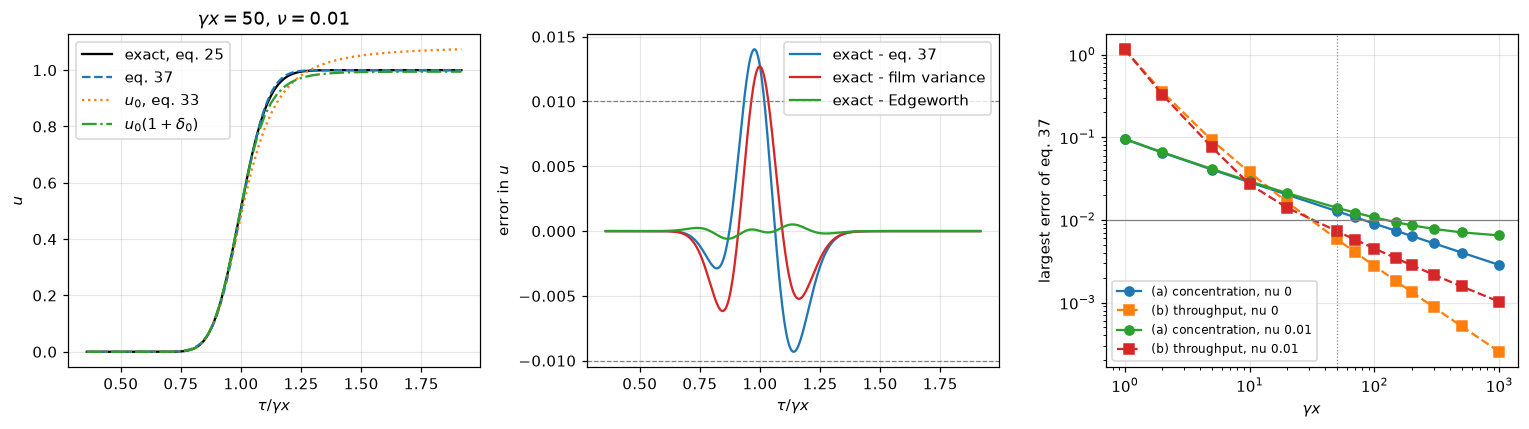

In [11]:
# Figure: the curves at T, the error against tau, and both readings against gx.
_lo, _hi = window(GX_T, NU_T)
_tau = np.linspace(_lo, _hi, 400)
_E = exact_for(GX_T, NU_T)
_u = _E.u(2 * _tau / 3)
_tau_s = np.linspace(_lo, _hi, 60)
_sad = np.array([saddle(GX_T, NU_T, 2 * t / 3) for t in _tau_s])
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].plot(_tau / GX_T, _u, "k", label="exact, eq. 25")
ax[0].plot(_tau / GX_T, u37(_tau, GX_T), "C0--", label="eq. 37")
ax[0].plot(_tau_s / GX_T, _sad[:, 1], "C1:", label="$u_0$, eq. 33")
ax[0].plot(_tau_s / GX_T, _sad[:, 1] * (1 + _sad[:, 2]), "C2-.", label=r"$u_0(1+\delta_0)$")
ax[0].set(xlabel=r"$\tau/\gamma x$", ylabel="$u$", title=r"$\gamma x = 50$, $\nu = 0.01$")
ax[0].legend()
ax[1].plot(_tau / GX_T, _u - u37(_tau, GX_T), "C0", label="exact - eq. 37")
ax[1].plot(_tau / GX_T, _u - u_filmvar(_tau, GX_T, NU_T), "C3", label="exact - film variance")
ax[1].plot(_tau / GX_T, _u - u_edgeworth(_tau, GX_T, NU_T), "C2", label="exact - Edgeworth")
for s in (1, -1):
    ax[1].axhline(s * THRESH, color="grey", lw=0.8, ls="--")
ax[1].set(xlabel=r"$\tau/\gamma x$", ylabel="error in $u$")
ax[1].legend()
for j, n in ((0, 0.0), (-1, NU_T)):
    ax[2].loglog(GX_LADDER, R3X["A"][:, j], "o-", label=f"(a) concentration, nu {n:g}")
    ax[2].loglog(GX_LADDER, R3X["B"][:, j], "s--", label=f"(b) throughput, nu {n:g}")
ax[2].axhline(THRESH, color="grey", lw=0.8)
ax[2].axvline(50, color="grey", lw=0.8, ls=":")
ax[2].set(xlabel=r"$\gamma x$", ylabel="largest error of eq. 37")
ax[2].legend(fontsize=8)
fig.tight_layout()
plt.show()

## Validation

### V1 to V3. Two inversions, the moments and the limits

V1 compares the quadrature of eq. 25 with Talbot inversion at T on 41 values of $\tau$ and
at $\gamma x = 1$ and 500 for $\nu = 0$ and 0.01 (Table IV's points are in R2). V2 checks the
zeroth and first time moments of the computed curve against the mass balance,
$\int_0^\infty (1 - u)\,d\tau = \gamma x$ (the half-value speed $mv/(m + K)$ of p. 393), and
$\int_0^\infty 2\tau(1 - u)\,d\tau = k_2 + (\gamma x)^2$. V3: at $\nu = 0$ the effluent starts
at zero (p. 391); at $\nu > 0$ the integral at $\sigma\theta = 0$ is the midpoint of the jump,
$e^{-\gamma x/\nu}/2$; the impulse response integrated over a step equals the change of $u$
(the termwise derivative of the same quadrature sum: an identity, which no break row can move).

In [12]:
def moments(gx, nu, K=K0, nu_exact=None, npp_tau=20):
    lo, hi = 0.0, gx + 40 * np.sqrt(cumulants(gx, nu)[1])
    E = Exact(gx, nu if nu_exact is None else nu_exact, st_max=2 * hi / 3, K=K)
    sd = np.sqrt(cumulants(gx, nu)[1])
    edges = np.linspace(lo, hi, int(np.ceil((hi - lo) / (sd / 4))) + 1)
    x, w = np.polynomial.legendre.leggauss(npp_tau)
    a, b = edges[:-1, None], edges[1:, None]
    t = ((b - a) / 2 * x + (b + a) / 2).ravel()
    wt = ((b - a) / 2 * w).ravel()
    one_m = 1 - E.u(2 * t / 3)
    m0, m1 = wt @ one_m, wt @ (2 * t * one_m)
    k1, k2, _ = cumulants(gx, nu)
    return abs(m0 / k1 - 1), abs(m1 / (k2 + k1 ** 2) - 1)


def study_v(K=K0, talbot_gx_factor=1.0, nu_exact=None, npp=20, L=None, show=False):
    # V1: two inversions
    lo, hi = window(GX_T, NU_T)
    taus = np.linspace(lo, hi, 41)
    ne = NU_T if nu_exact is None else nu_exact
    E = Exact(GX_T, ne, st_max=2 * hi / 3, K=K, npp=npp, L=L)
    gq = E.u(2 * taus / 3)
    gt = np.array([talbot(GX_T, NU_T, 2 * t / 3, gx_factor=talbot_gx_factor) for t in taus])
    gap_T = np.max(np.abs(gq - gt))
    gaps = []
    for g in (1.0, 500.0):
        for n in (0.0, NU_T):
            lo_, hi_ = window(g, n)
            ts = np.linspace(lo_, hi_, 7)[1:-1]
            Eg = Exact(g, n if (nu_exact is None or n == 0) else nu_exact, st_max=2 * hi_ / 3,
                       K=K, npp=npp, L=L)
            gaps.append(np.max(np.abs(Eg.u(2 * ts / 3) - np.array(
                [talbot(g, n, 2 * t / 3, gx_factor=talbot_gx_factor) for t in ts]))))
    # V2: moments
    mom = {}
    for g in (1.0, 50.0):
        for n in (0.0, NU_T):
            mom[(g, n)] = moments(g, n, K, nu_exact if n == NU_T else None)
    m0 = max(v[0] for v in mom.values())
    m1 = max(v[1] for v in mom.values())
    # V3: limits
    z0 = max(abs(Exact(g, 0.0, st_max=0.0, K=K).u(0.0)[0]) for g in (1.0, 50.0))
    Ej = Exact(1.0, 0.5, st_max=0.0, K=K, L=1e5, hmax=0.5, npp=8)
    tail = -K["c_int"] * np.exp(-2.0) * 1.0 / (2 * 0.25 * 1e5)   # P5 tail beyond L
    jump = abs(Ej.u(0.0)[0] + tail - np.exp(-2.0) / 2)
    s1, s2 = 2 * (GX_T - 2) / 3, 2 * (GX_T + 2) / 3
    x, w = np.polynomial.legendre.leggauss(40)
    ss = (s2 - s1) / 2 * x + (s2 + s1) / 2
    imp = abs((s2 - s1) / 2 * (w @ E.dudst(ss)) - (E.u(s2)[0] - E.u(s1)[0]))
    if show:
        print(f"V1: quadrature against Talbot, largest gap at T (41 tau) below 1e-12 "
              f"(here {gap_T:.1e})")
        print("    at gx 1 and 500, nu 0 and 0.01: below 1e-12 (here "
              + ", ".join(f"{v:.1e}" for v in gaps) + ")")
        print("V2: relative gaps of the moments (zeroth, first):")
        for (g, n), (a, b) in mom.items():
            print(f"    gx {g:g}, nu {n:g}: below 1e-10 (here {a:.1e}, {b:.1e})")
        print(f"V3: u at st = 0, nu = 0 (gx 1 and 50): below 1e-12 (here {z0:.1e})")
        print(f"    nu 0.5, gx 1, st = 0 against exp(-gx/nu)/2: below 1e-10 (here {jump:.1e})")
        print(f"    impulse response over a step: below 1e-12 (here {imp:.1e})")
    return {
        "v1_gap_T": (gap_T, dict(kind="bound", max=1e-12, basis="tolerance",
                                 note="quadrature against Talbot at T, 41 tau")),
        "v1_gap_ladder": (max(gaps), dict(kind="bound", max=1e-12, basis="tolerance",
                                          note="the same at gx 1 and 500, nu 0 and 0.01")),
        "v2_m0_gap": (m0, dict(kind="bound", max=1e-10, basis="tolerance",
                               note="relative gap of int (1 - u) dtau against gx")),
        "v2_m1_gap": (m1, dict(kind="bound", max=1e-10, basis="tolerance",
                               note="relative gap of int 2 tau (1 - u) dtau against k2 + gx^2")),
        "v3_start_nu0": (z0, dict(kind="bound", max=1e-12, basis="theory",
                                  note="u at st = 0 for nu = 0 (p. 391)")),
        "v3_jump_mid": (jump, dict(kind="bound", max=1e-10, basis="theory",
                                   note="integral at st = 0 against exp(-gx/nu)/2, nu 0.5, gx 1, "
                                        "tail beyond L = 1e5 added")),
        "v3_impulse": (imp, dict(kind="bound", max=1e-12, basis="identity", structural=True,
                                 note="impulse response integrated over a step against the change of u")),
    }


V = study_v(show=True)

V1: quadrature against Talbot, largest gap at T (41 tau) below 1e-12 (here 5.5e-16)
    at gx 1 and 500, nu 0 and 0.01: below 1e-12 (here 3.3e-16, 2.2e-16, 4.4e-16, 4.4e-16)
V2: relative gaps of the moments (zeroth, first):
    gx 1, nu 0: below 1e-10 (here 7.8e-16, 5.6e-15)
    gx 1, nu 0.01: below 1e-10 (here 4.4e-16, 1.1e-14)
    gx 50, nu 0: below 1e-10 (here 0.0e+00, 5.6e-16)
    gx 50, nu 0.01: below 1e-10 (here 3.3e-16, 1.4e-15)
V3: u at st = 0, nu = 0 (gx 1 and 50): below 1e-12 (here 7.2e-16)
    nu 0.5, gx 1, st = 0 against exp(-gx/nu)/2: below 1e-10 (here 8.6e-12)
    impulse response over a step: below 1e-12 (here 5.6e-17)


### V4. Eq. 24 against the series of eq. 18

$y_D(i\sigma\lambda^2) = 2\sum_n i\lambda^2/(i\lambda^2 + n^2\pi^2/2)$, summed to $N$ terms with
the leading tail $\sum_{n>N} 4i\lambda^2/(n^2\pi^2)$ added, against `hd` at Table II's
$\lambda$; the next tail term is $O(\lambda^4/N^3)$.

In [13]:
def study_v4(K=K0, N=200000):
    lam = T2["lam"].iloc[1:-1].astype(float).to_numpy()
    n = np.arange(1, N + 1, dtype=float)[:, None]
    il2 = 1j * lam ** 2
    s = 2 * np.sum(il2 / (il2 + n ** 2 * np.pi ** 2 / 2), axis=0)
    tail = 4 * il2 / np.pi ** 2 * (1 / N - 1 / (2 * N ** 2) + 1 / (6 * N ** 3))
    a, b = hd(lam, K)
    gap = np.max(np.abs(s + tail - (a + 1j * b)))
    nxt = np.max(8 * lam ** 4 / (3 * np.pi ** 4 * N ** 3))
    print(f"V4: series of eq. 18 against eq. 24 at Table II's lambda: largest gap below 1e-10 "
          f"(here {gap:.1e}; next tail term {nxt:.1e})")
    return {"v4_series_gap": (gap, dict(kind="bound", max=1e-10, basis="tolerance",
                                        note="eq. 18 summed with its tail against eq. 24"))}


V4 = study_v4()

V4: series of eq. 18 against eq. 24 at Table II's lambda: largest gap below 1e-10 (here 1.1e-12; next tail term 1.4e-15)


### V5. Quadrature convergence and the production error

Composite 2-point Gauss-Legendre (order 4) on halved panels (both the width limit, from 0.4,
and the phase limit, from $4\pi$, halved), seven levels, at Table IV's $(\gamma x, \sigma\theta) = (1, 1.0)$ and at
T ($\tau = \gamma x$), with the upper end $L$ held fixed; `observed_orders` on the ladder and the
round-off companion $\epsilon\sum|wf|$. The production rule (20 nodes, width 0.05, phase
step $\pi$, $\gamma x H_1(L) = 40$) has as its error the change when all four refine together
(30 nodes, 0.025, $\pi/2$, 60). The observed orders scatter between their printed minimum and
maximum around the theory value 4, because the error oscillates with the phase of the panels;
the claim is a band of 3 to 7, widened to this after the seven-level ladder reached about 6.6
at Table IV's condition; a rule of order 2 or a wrong refinement ratio still leaves it.

In [14]:
def study_v5(K=K0, npp_prod=20, npp_ladder=2, scale=1, ratio_true=2.0, show=False):
    out = {}
    for tag, (g, n, s) in (("t4", (1.0, 0.0, 1.0)), ("T", (GX_T, NU_T, 2 * GX_T / 3))):
        Ep = Exact(g, n, st_max=s, K=K, npp=npp_prod)
        Lfix = Ep.L
        lev = [scale * 2 ** i for i in range(7)]
        kf = lambda k: scale * ratio_true ** np.log2(k / scale)   # the panels refined per level
        lad = observed_orders(lambda k: Exact(g, n, st_max=s, K=K, npp=npp_ladder, hmax=0.4 / kf(k),
                                              dphi=4 * np.pi / kf(k), L=Lfix).u(s)[0], lev)
        fin = abs(lad["values"][-1] - lad["values"][-2])
        ro = Exact(g, n, st_max=s, K=K, npp=npp_ladder, hmax=0.4 / kf(lev[-1]), dphi=4 * np.pi / kf(lev[-1]),
                   L=Lfix).roundoff(s)[0]
        Ef = Exact(g, n, st_max=s, K=K, npp=30, hmax=0.025, dphi=np.pi / 2, Lcut=60.0)
        prod = abs(Ep.u(s)[0] - Ef.u(s)[0])
        if show:
            print(f"{tag}: values " + ", ".join(f"{v:.12f}" for v in lad["values"]))
            print(f"     orders " + ", ".join(f"{v:.1f}" for v in lad["orders"])
                  + f"; finest difference {fin:.0e}, round-off (here {ro:.1e})")
            print(f"     production error below 1e-13 (here {prod:.1e})")
        if scale == 1:   # on a ladder down at round-off (scale > 1) the orders are noise:
            # that row tests the round-off companion only
            out[f"v5_order_min_{tag}"] = (min(lad["orders"]), dict(
                kind="bound", min=3.0, max=7.0, basis="theory",
                note="2-point Gauss-Legendre, order 4; the orders scatter around 4 as the error "
                     "oscillates in the panel phase, a 3-point rule (order 6) or a wrong refinement ratio leaves the band"))
            out[f"v5_order_max_{tag}"] = (max(lad["orders"]), dict(
                kind="bound", min=3.0, max=7.0, basis="theory",
                note="2-point Gauss-Legendre, order 4; the orders scatter around 4 as the error "
                     "oscillates in the panel phase, a 3-point rule (order 6) or a wrong refinement ratio leaves the band"))
        out[f"v5_finest_over_roundoff_{tag}"] = (fin / ro, dict(
            kind="bound", min=100.0, basis="theory",
            note="finest ladder difference over eps sum |w f|"))
        out[f"v5_production_err_{tag}"] = (prod, dict(
            kind="bound", max=1e-13, basis="tolerance",
            note="production rule against all four knobs refined together"))
    return out


V5 = study_v5(show=True)

t4: values 0.814395959027, 0.814416680827, 0.814416024566, 0.814415995703, 0.814415994750, 0.814415994760, 0.814415994759
     orders 5.0, 4.5, 4.9, 6.6, 4.9; finest difference 3e-13, round-off (here 8.0e-17)
     production error below 1e-13 (here 2.2e-16)


T: values 0.512686847879, 0.512702082003, 0.512702395749, 0.512702423679, 0.512702424894, 0.512702424932, 0.512702424935
     orders 5.6, 3.5, 4.5, 5.0, 3.8; finest difference 3e-12, round-off (here 2.8e-18)
     production error below 1e-13 (here 0.0e+00)


### The functions against the check values

Every row of `check_values.csv` (a second route: de Hoog inversion at 40 digits and
closed forms, a separate script) is reproduced by the page's functions to its tolerance
before any claim is registered.

In [15]:
CV = {}
_a, _b = hd(np.array([1.3, 4.5, 0.5]))
CV.update(HD1_lam1p3=_a[0], HD2_lam1p3=_b[0], HD1_lam4p5=_a[1],
          HD1_series_reldev_lam0p5=(4 / 45) * 0.5 ** 4 / _a[2] - 1,
          HD2_series_reldev_lam0p5=(2 / 3) * 0.5 ** 2 / _b[2] - 1)
CV.update({f"D{i}_lamr1": d for i, d in enumerate(d_n(1.0))})
CV.update(u0_limit_inf=R2X["u0_inf"], delta0_limit_inf=R2X["d0_inf"],
          u0_1pdelta0_limit_inf=R2X["u0_inf"] * (1 + R2X["d0_inf"]))
CV.update(zip(("kappa1_T", "kappa2_T", "kappa3_T"), cumulants(GX_T, NU_T)))
CV["u_T_mid"] = _E.u(2 * GX_T / 3)[0]
_T = R3X["T"]
CV.update(erf_maxerr_T=_T["a"], erf_argmax_tau_over_gx_T=_T["a_loc"],
          filmvar_maxerr_T=_T["fv"], filmvar_argmax_tau_over_gx_T=_T["fv_loc"],
          edgeworth_maxerr_T=_T["ew"], edgeworth_argmax_tau_over_gx_T=_T["ew_loc"])
CV.update(tau_exact_u0p05_T=_T["tau"][0], tau_relerr_erf_u0p05_T=_T["rel"][0],
          tau_exact_u0p95_T=_T["tau"][-1], tau_relerr_erf_u0p95_T=_T["rel"][-1])
CV.update(zip(("saddle_lam0_T", "saddle_u0_T", "saddle_delta0_T"),
              saddle(GX_T, NU_T, 2 * GX_T / 3)))
CV["ldf_u_T_mid"] = Exact(GX_T, NU_T, st_max=2 * GX_T / 3, form="ldf").u(2 * GX_T / 3)[0]
CV["erf_floor_nu0p01"] = R3["r3_floor_nu0p01"][0]
# the root again with the value at each maximum from Talbot (its location from the quadrature):
# the root then does not move with the BLAS kernel in its last digits
CV["erf_gx_at_1pct_nu0p01"] = gx_root(NU_T, "a", lo=100.0, hi=150.0, talbot_value=True,
                                       xtol=1e-13)
DEV = assert_check_values(CV, page=PAGE)
print(f"{len(DEV)} check values reproduced to their rtol; largest relative deviation "
      f"(here {max(abs(v) for v in DEV.values()):.1e}, {max(DEV, key=lambda k: abs(DEV[k]))})")

check values: 33 of 33 agree, worst relative -2.8e-12
33 check values reproduced to their rtol; largest relative deviation (here 2.8e-12, HD2_series_reldev_lam0p5)


### The finding

Under each reading, at the corner of the stated range and from which bed length on, each
number against the exact route's own error (V1, V5: the exact curve is pinned far below the
0.01 that decides):

In [16]:
_err = max(V["v1_gap_T"][0], V["v1_gap_ladder"][0], V5["v5_production_err_T"][0])
print(f"Exact route: two inversions agree below 1e-12 (here {_err:.1e}) at the conditions checked.")
print(f"(a) concentration: eq. 37 misses 1 % at gx 50 (largest error {R3['r3_a_gx50_nu0'][0]:.4f} "
      f"at nu 0, {R3['r3_a_T'][0]:.4f} at nu 0.01); it holds from gx {R3['r3_gx_a_nu0'][0]:.0f} "
      f"(nu 0) and {R3['r3_gx_a_nu0p01'][0]:.0f} (nu 0.01); {R3['r3_a_nodes_fail'][0]} of {_nb} "
      f"nodes with gx >= 50 fail.")
print(f"(b) throughput on {R3['r3_band_lo'][0]} to {R3['r3_band_hi'][0]}: eq. 37 is within 1 % at gx 50 ({100 * R3['r3_b_gx50_nu0'][0]:.2f} % at nu 0, "
      f"{100 * R3['r3_b_T'][0]:.2f} % at nu 0.01); it holds from gx {R3['r3_gx_b_nu0'][0]:.0f} "
      f"(nu 0) and {R3['r3_gx_b_nu0p01'][0]:.0f} (nu 0.01); {R3['r3_b_nodes_fail'][0]} of {_nb} "
      f"nodes with gx >= 50 fail.")
print(f"Cause at T: the third cumulant removes a factor {R4['r4_skew_factor'][0]:.1f} of the "
      f"error left by the film variance ({R4['r4_filmvar_T'][0]:.4f} to {R4['r4_edgeworth_T'][0]:.5f}).")

Exact route: two inversions agree below 1e-12 (here 5.5e-16) at the conditions checked.
(a) concentration: eq. 37 misses 1 % at gx 50 (largest error 0.0128 at nu 0, 0.0140 at nu 0.01); it holds from gx 81 (nu 0) and 122 (nu 0.01); 12 of 40 nodes with gx >= 50 fail.
(b) throughput on 0.05 to 0.95: eq. 37 is within 1 % at gx 50 (0.59 % at nu 0, 0.73 % at nu 0.01); it holds from gx 31 (nu 0) and 32 (nu 0.01); 0 of 40 nodes with gx >= 50 fail.
Cause at T: the third cumulant removes a factor 21.3 of the error left by the film variance (0.0127 to 0.00060).


**Reading the numbers.** Reading (b), the throughput at which a given fraction of the feed
breaks through, on the band of fractions printed above, is within 1 percent of eq. 37 over
the whole stated range. That verdict depends on the band: the largest error sits at an end
of the band, and the roots printed above give the band ends at which it reaches 1 percent at
$\gamma x = 50$; on the wider band it exceeds 1 percent there. The sentence attaches the
percent to the expression for $u$, so (a) is the direct reading, and under it the statement
does not hold at $\gamma x = 50$: the largest error there is above 0.01 of the feed, and the
bed must be longer, until $\gamma x$ reaches the roots printed above, more so with a film. The error comes
from the skewness of the exact curve, which eq. 37, symmetric by construction, cannot
carry; the film variance it also omits leaves a floor at $\nu > 0$. Nothing here concerns
eq. 36 ("accurate to 0.5 percent", quoted only), the film criterion
$\gamma x/\nu > 5$ (p. 391), elution (eq. 7), axial dispersion, or later corrected forms of
eq. 37, which the page has not read.

## What pymrm adds

Checks only. The answer is a closed form, a real integral and a Laplace inversion; no pymrm
operator or solver is used. pymrm contributes `pymrm.checks.find_roots` for the cut-off of
the integral, $\lambda_0$ of eq. 32 (with its uniqueness), every maximum as a root of a
derivative, $\tau(u)$ and the bed lengths at which eq. 37 reaches 1 percent, and
`pymrm.checks.observed_orders` for the quadrature ladder. A bed with resolved spheres would be
a third, transform-free route; that is the subject of `J1.8` (planned).

## Reuse

- For a linear bed with film and solid diffusion in spheres, `Exact(gx, nu, st_max)` gives
  the breakthrough curve below 1e-12 where checked for $\sigma\theta \le$ `st_max`; `talbot` is the
  independent check. Both need only the three groups.
- Use eq. 37 for throughput (the time to reach a given breakthrough fraction) in the stated
  range; for concentrations within 0.01 of the feed use the exact curve, or the Edgeworth
  form with the film included, which is much closer at the same cost.
- Another particle model changes only $y_D(s)$: the `ldf` form of `Exact` is the
  linear-driving-force particle of [`J1.5`](../J1.5-ldf-breakthrough/) in the same inversion.

**Related pages.** [`J1.5`](../J1.5-ldf-breakthrough/) (the single sphere and the LDF
constant), `J1.6` (planned) (Thomas and Bohart-Adams),
`J1.8` (planned) (the general rate model, numerical),
[`J1.10`](../J1.10-van-deemter-plate-height/) (moments and plate height).

**Cite the source, not this page:** Rosen, J. B., *Kinetics of a fixed bed system for
solid diffusion into spherical particles*, Journal of Chemical Physics **20** 387-394
(1952), [doi:10.1063/1.1700431](https://doi.org/10.1063/1.1700431).

### Claims and the defect-injection table

Every number above is registered as a claim. Each row breaks one thing on purpose through
an argument of the studies above, re-runs every study that argument enters, and records
whether each claim's own check catches the change.

In [17]:
BASE = {"R1": R1, "R2": R2, "R3": R3, "R4": R4, "V": V, "V4": V4, "V5": V5}
for study in BASE.values():
    for name, (val, spec) in study.items():
        spec = dict(spec)
        kind = spec.pop("kind")
        if kind == "count":
            claims.count(name, spec.pop("values"), spec.pop("threshold"), **spec)
        elif kind == "exact":
            claims.exact(name, val, **spec)
        else:
            getattr(claims, kind)(name, val, **spec)

STUDY_FN = {"R1": lambda **k: study_r1(**k)[0], "R2": lambda **k: study_r2(**k)[0],
            "R3": lambda **k: study_r3(**k)[0], "R4": study_r4, "V": study_v,
            "V4": study_v4, "V5": study_v5}
K_SWAP = dict(K0, swap_hd=True)
K_SIN = dict(K0, hd1_sin_sign=-1.0)
K_PI = dict(K0, c_int=1 / np.pi)
K_GX3 = dict(K0, erf_div=3.0)
K_E3 = dict(K0, e3_const=2.0)
K_B1 = dict(K0, b_pow=1)
K_PI1 = dict(K0, c_int=1.01 * 2 / np.pi)
K_2PI = dict(K0, two_pi=np.pi)
K_D0 = dict(K0, d0_sign=-1.0)
ROWS = [
    ("H_D1 and H_D2 swapped", {"R1": dict(K=K_SWAP), "V4": dict(K=K_SWAP)}),
    ("sin 2l in H_D1 with the wrong sign", {"R1": dict(K=K_SIN), "R2": dict(K=K_SIN),
                                            "V": dict(K=K_SIN), "V4": dict(K=K_SIN)}),
    ("2/pi -> 1/pi in eq. 25", {"R2": dict(K=K_PI), "V": dict(K=K_PI), "V5": dict(K=K_PI)}),
    ("eq. 25 prefactor 1 % high", {"R3": dict(K=K_PI1), "R4": dict(K=K_PI1)}),
    ("(2 pi)^(1/2) -> pi^(1/2) in eq. 33", {"R2": dict(K=K_2PI)}),
    ("u0 (1 - delta0) for u0 (1 + delta0)", {"R2": dict(K=K_D0)}),
    ("consistency allowance: last digit only", {"R2": dict(cons_inputs=False)}),
    ("3-point rule in the quadrature ladder", {"V5": dict(npp_ladder=3)}),
    ("ladder started 64 times finer", {"V5": dict(scale=64)}),
    ("ladder refined by 1.5 per level, orders taken for 2", {"V5": dict(ratio_true=1.5)}),
    ("(gx/3)^(1/2) for (gx/5)^(1/2) in eq. 37", {"R3": dict(K=K_GX3), "R4": dict(K=K_GX3)}),
    ("nu = 0 inside the exact route at nu = 0.01", {"R3": dict(nu_exact=0.0),
                                                    "V": dict(nu_exact=0.0)}),
    ("E3 with +2 for -2 (Table III)", {"R2": dict(K=K_E3)}),
    ("B = l csch l, not squared (Table III)", {"R2": dict(K=K_B1)}),
    ("Talbot at gx x 1.01", {"R2": dict(talbot_gx_factor=1.01), "V": dict(talbot_gx_factor=1.01)}),
    ("cut-off L = 2", {"R2": dict(L=2.0), "V": dict(L=2.0)}),
    ("2 nodes per panel in production", {"R2": dict(npp=2), "V": dict(npp=2),
                                         "V5": dict(npp_prod=2)}),
    ("band 0.10 to 0.90 for reading (b)", {"R3": dict(band=(0.10, 0.90))}),
]
claims.define_rows([lab for lab, _ in ROWS])
TABLE, CRASHED, NO_NUMBER = [], [], []
for label, studies in ROWS:
    for sname, kw in studies.items():
        try:
            broken = STUDY_FN[sname](**kw)
        except Exception as exc:       # a crash is reported, never counted as a catch
            print(f"CRASH {label} / {sname}: {type(exc).__name__}: {exc}")
            CRASHED.append((label, sname))
            continue
        for name in BASE[sname]:
            if name not in broken:
                continue
            val = broken[name][0]
            if not np.isfinite(val):   # no number came back: not a moved value
                NO_NUMBER.append((label, name))
                continue
            TABLE.append((label, name, claims[name], val, claims.breaks(label, name, val)))
print(f"{len(CRASHED)} study crash(es); {len(NO_NUMBER)} claim(s) came back without a number "
      "in a broken run and are not counted.")
print(f"{'row':44s} {'claim':34s} {'caught':>6s}")
for label, name, v0, v1, caught in TABLE:
    if caught:
        print(f"{label[:44]:44s} {name[:34]:34s} {'yes':>6s}")
print(f"runtime (here {time.perf_counter() - T_START:.0f} s)")

V4: series of eq. 18 against eq. 24 at Table II's lambda: largest gap below 1e-10 (here 1.6e+00; next tail term 1.4e-15)


CRASH sin 2l in H_D1 with the wrong sign / V: RuntimeError: cut-off of eq. 25: 3 roots
V4: series of eq. 18 against eq. 24 at Table II's lambda: largest gap below 1e-10 (here 4.4e-01; next tail term 1.4e-15)


1 study crash(es); 4 claim(s) came back without a number in a broken run and are not counted.
row                                          claim                              caught
H_D1 and H_D2 swapped                        r1_cells_off_print                    yes
H_D1 and H_D2 swapped                        r1_largest_halfunits                  yes
H_D1 and H_D2 swapped                        r1_hd1_series_reldev                  yes
H_D1 and H_D2 swapped                        r1_hd2_series_reldev                  yes
H_D1 and H_D2 swapped                        r1_hd1_asym_gap                       yes
H_D1 and H_D2 swapped                        r1_hd2_asym_gap                       yes
H_D1 and H_D2 swapped                        v4_series_gap                         yes
sin 2l in H_D1 with the wrong sign           r1_cells_off_print                    yes
sin 2l in H_D1 with the wrong sign           r1_largest_halfunits                  yes
sin 2l in H_D1 with the wrong sign  

In [18]:
# Claims: every registered number printed, agreement.json written for CI, and an
# exception raised when a claim fails its own check or has no break row.
claims.report();   # the semicolon keeps the notebook from echoing the payload

Claims for J1.7:
  r1_cells_off_print         = 8                exact  exact, margin 0.00266
  r1_cells_total             = 80               exact  exact
  r1_largest_halfunits       = 1.7054           value  rtol 1e-06
  r1_hd1_series_reldev       = 0.0023805        value  rtol 1e-06
  r1_hd2_series_reldev       = 0.0015858        value  rtol 1e-06
  r1_hd1_asym_gap            = 0.00076272       value  rtol 1e-06
  r1_hd2_asym_gap            = 0.0014695        value  rtol 1e-06
  r2_u_cells_off_print       = 1                exact  exact, margin 0.0789
  r2_u_total                 = 5                exact  exact
  r2_u_st1p0                 = 0.81442          value  rtol 1e-06
  r2_u_st1p0_halfunits       = 12.832           value  rtol 1e-06
  r2_u_st1p5                 = 0.95161          value  rtol 1e-06
  r2_l0_cells_off_print      = 3                exact  exact, margin 0.00161
  r2_u0_cells_off_print      = 6                exact  exact, margin 0.328
  r2_d0_cells_off_print     